# Multiclass Classification

Our dataset consists of clinical data from patients who entered the hospital complaining of chest pain ("angina") during exercise.  The information collected includes:

* `age` : Age of the patient

* `sex` : Sex of the patient

* `cp` : Chest Pain type

    + Value 0: asymptomatic
    + Value 1: typical angina
    + Value 2: atypical angina
    + Value 3: non-anginal pain
   
    
* `trtbps` : resting blood pressure (in mm Hg)

* `chol` : cholesterol in mg/dl fetched via BMI sensor

* `restecg` : resting electrocardiographic results

    + Value 0: normal
    + Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
    + Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria

* `thalach` : maximum heart rate achieved during exercise

* `output` : the doctor's diagnosis of whether the patient is at risk for a heart attack
    + 0 = not at risk of heart attack
    + 1 = at risk of heart attack

In [1]:
## library imports here
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from plotnine import *

First we'll create binary variables for each class.

In [2]:
ha = pd.read_csv("https://www.dropbox.com/s/aohbr6yb9ifmc8w/heart_attack.csv?dl=1")

ha["cp_is_3"] = ((ha["cp"] == 3) * 1)
ha["cp_is_2"] = ((ha["cp"] == 2) * 1)
ha["cp_is_1"] = ((ha["cp"] == 1) * 1)
ha["cp_is_0"] = ((ha["cp"] == 0) * 1)

# strings for the purposes of plotting
ha["cp"] = ha["cp"].astype("str")
ha

,age,sex,cp,trtbps,chol,restecg,thalach,output,cp_is_3,cp_is_2,cp_is_1,cp_is_0
0,63,1,3,145,233,0,150,1,1,0,0,0
1,37,1,2,130,250,1,187,1,0,1,0,0
2,56,1,1,120,236,1,178,1,0,0,1,0
3,57,0,0,120,354,1,163,1,0,0,0,1
4,57,1,0,140,192,1,148,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
268,59,1,0,164,176,0,90,0,0,0,0,1
269,57,0,0,140,241,1,123,0,0,0,0,1
270,45,1,3,110,264,1,132,0,1,0,0,0
271,68,1,0,144,193,1,141,0,0,0,0,1


The target is `cp` which has 4 categories. How common is each category?

In [3]:
ha["cp"].value_counts().sort_index()

cp
0    128
1     44
2     81
3     20
Name: count, dtype: int64

Let's consider as predictors: `trtbps`, `chol`, `age`.

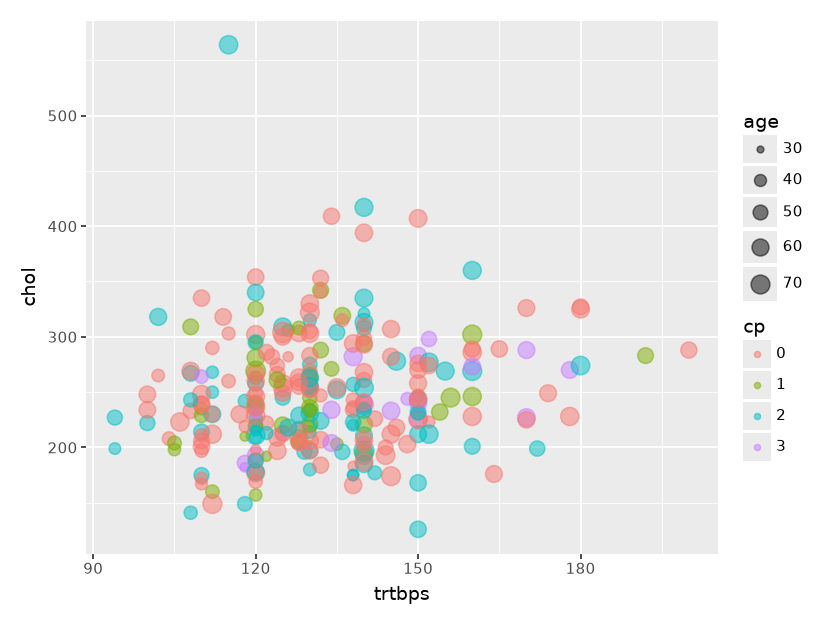

In [4]:
(ggplot(ha, aes(x="trtbps", y="chol", size = "age", color="cp"))
+ geom_point(alpha = 0.5))

## Q1: A Natural Multiclass Model: k-nearest neighbors

Fit a multiclass 10-nearest neighbors model. Output the predicted class probabilities and plot the predicted classes for the training data. Estimate the test:

- accuracy
- macro precision, recall, and F1 scores
- precision, recall, and F1 score for each class. You will likely get some weird values; can you explain why?


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

In [6]:
features = ["trtbps", "chol", "age"]


X = ha[features]
y = ha["cp"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["chol", "age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["trtbps"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)
knn = make_pipeline(preprocessor, KNeighborsClassifier(n_neighbors=10))
knn.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['0','1','2','3']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['trtbps','chol','age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...), ('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, 

### Predicted class probabilities

In [7]:
y_pred_train = knn.predict(X_train)
y_prob_train = knn.predict_proba(X_train)
prob_df = pd.DataFrame(
    y_prob_train,
    columns=knn.classes_,
    index=X_train.index
)

prob_df["Actual"] = y_train
prob_df["Predicted"] = y_pred_train

prob_df.head()

,0,1,2,3,Actual,Predicted
87,0.8,0.0,0.0,0.2,3,0
18,0.2,0.3,0.5,0.0,2,2
177,0.6,0.3,0.1,0.0,0,0
214,0.4,0.2,0.3,0.1,0,0
65,0.5,0.2,0.3,0.0,0,0


In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

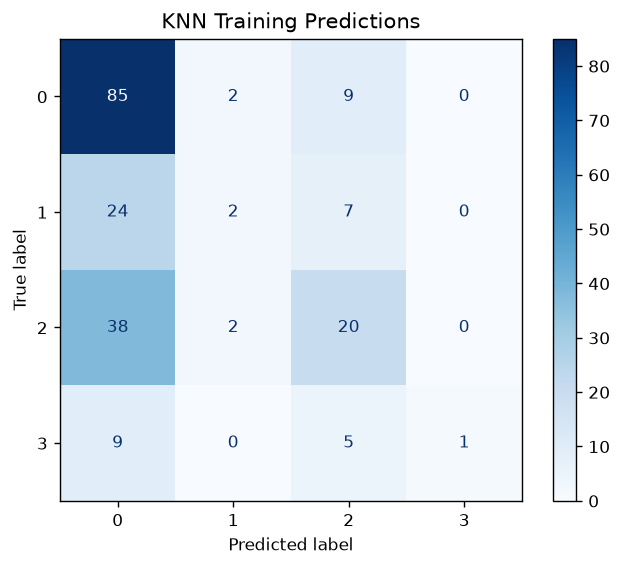

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_train,
    display_labels=knn.classes_,
    cmap="Blues"
)

plt.title("KNN Training Predictions")
plt.show()

Estimate the test:

- accuracy
- macro precision, recall, and F1 scores
- precision, recall, and F1 score for each class. You will likely get some weird values; can you explain why?

In [10]:
from sklearn.metrics import accuracy_score

**Estimated test accuracy**

In [11]:
y_pred_test = knn.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred_test)
print(test_accuracy)

0.43478260869565216


**Estimated macro scores**

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [13]:
test_precision = precision_score(y_test, y_pred_test, average="macro")
test_recall = recall_score(y_test, y_pred_test, average="macro")
test_f1 = f1_score(y_test, y_pred_test, average="macro")

print("Test Macro Precision:", test_precision)
print("Test Macro Recall:", test_recall)
print("Test Macro F1:", test_f1)

Test Macro Precision: 0.3214285714285714
Test Macro Recall: 0.27384334415584416
Test Macro F1: 0.2573260073260073


C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


**Scores for each class**

In [14]:
from sklearn.metrics import classification_report

In [15]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.50      0.72      0.59        32
           1       0.50      0.09      0.15        11
           2       0.29      0.29      0.29        21
           3       0.00      0.00      0.00         5

    accuracy                           0.43        69
   macro avg       0.32      0.27      0.26        69
weighted avg       0.40      0.43      0.38        69



C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


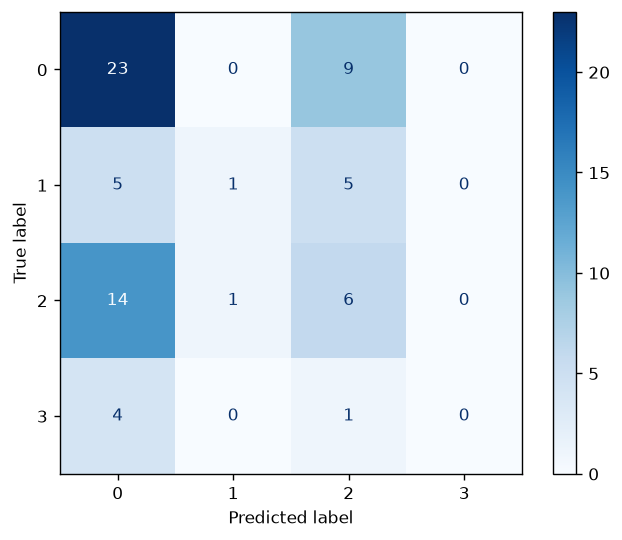

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    cmap="Blues"
)

plt.show()

The model did not appear to predict class 1 or 3 at all in the test set, resulting in scores of 0.00 across the board for both classes. This can likely be explained by a large imbalance in data distribution among the classes, as 128 observations are in class 0 and 81 observations are in class 2, whereas only 44 and 20 observations are in classes 1 and 3 respectively. This means that the model is much more likely to predict one of the two classes with the most observations, especially since KNN predicts based on the classes of nearby observations, classes with more observations may dominate the predictions.

## Q2:  OvR for Class 3



Fit a logistic regression model for predicting Class 3. Output the predicted class probabilities (Class 3 or not) and plot the predicted classes (Class 3 or not) for the training data. Estimate the test:

- precision, recall, and F1 score for class 3

In [17]:
features = ["trtbps", "chol", "age"]


X = ha[features]
y = ha["cp_is_3"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["chol", "age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["trtbps"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

log_mod = make_pipeline(preprocessor, LogisticRegression())
log_mod.fit(X_train, y_train)

y_pred_train_log = log_mod.predict(X_train)
y_prob_train_log = log_mod.predict_proba(X_train)
log_prob_df = pd.DataFrame(
    y_prob_train_log,
    columns=log_mod.classes_,
    index=X_train.index
)

log_prob_df["Actual"] = y_train
log_prob_df["Predicted"] = y_pred_train_log

log_prob_df.head()

,0,1,Actual,Predicted
29,0.944473,0.055527,0,0
228,0.950127,0.049873,0,0
253,0.916120,0.083880,0,0
129,0.966106,0.033894,0,0
41,0.928008,0.071992,0,0


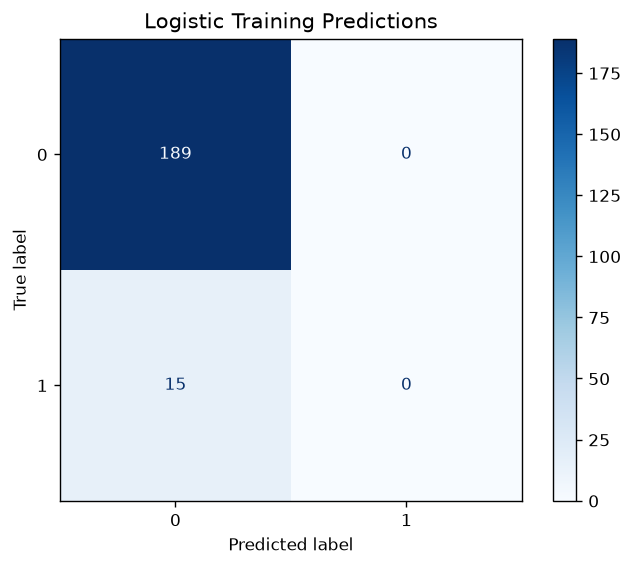

In [18]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_train_log,
    display_labels=log_mod.classes_,
    cmap="Blues"
)

plt.title("Logistic Training Predictions")
plt.show()

In [19]:
y_pred_test_log = log_mod.predict(X_test)
print(classification_report(y_test, y_pred_test_log))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96        64
           1       0.00      0.00      0.00         5

    accuracy                           0.93        69
   macro avg       0.46      0.50      0.48        69
weighted avg       0.86      0.93      0.89        69



C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


## Q3: OvR - Other classes.

Repeat Q2 for each of the other three `cp` categories.  Which category was the OvR approach best at distinguishing?

### Class = 0

In [20]:
X = ha[features]
y = ha["cp_is_0"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["chol", "age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["trtbps"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

log_mod = make_pipeline(preprocessor, LogisticRegression())
log_mod.fit(X_train, y_train)

y_pred_train_log = log_mod.predict(X_train)
y_prob_train_log = log_mod.predict_proba(X_train)
log_prob_df = pd.DataFrame(
    y_prob_train_log,
    columns=log_mod.classes_,
    index=X_train.index
)

log_prob_df["Actual"] = y_train
log_prob_df["Predicted"] = y_pred_train_log

log_prob_df.head()

,0,1,Actual,Predicted
161,0.506813,0.493187,1,0
238,0.407200,0.592800,1,1
254,0.605286,0.394714,1,0
190,0.303925,0.696075,1,1
245,0.430061,0.569939,1,1


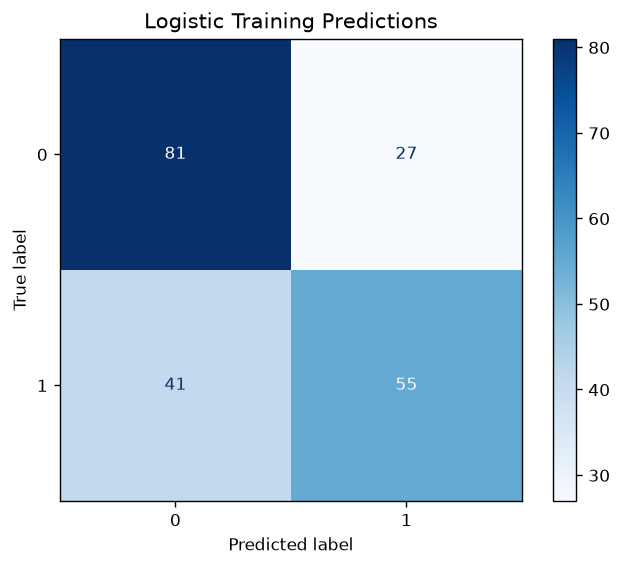

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_train_log,
    display_labels=log_mod.classes_,
    cmap="Blues"
)

plt.title("Logistic Training Predictions")
plt.show()

In [22]:
y_pred_test_log = log_mod.predict(X_test)
print(classification_report(y_test, y_pred_test_log))

              precision    recall  f1-score   support

           0       0.56      0.68      0.61        37
           1       0.50      0.38      0.43        32

    accuracy                           0.54        69
   macro avg       0.53      0.53      0.52        69
weighted avg       0.53      0.54      0.53        69



### Class = 1

In [23]:
X = ha[features]
y = ha["cp_is_1"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["chol", "age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["trtbps"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

log_mod = make_pipeline(preprocessor, LogisticRegression())
log_mod.fit(X_train, y_train)

y_pred_train_log = log_mod.predict(X_train)
y_prob_train_log = log_mod.predict_proba(X_train)
log_prob_df = pd.DataFrame(
    y_prob_train_log,
    columns=log_mod.classes_,
    index=X_train.index
)

log_prob_df["Actual"] = y_train
log_prob_df["Predicted"] = y_pred_train_log

log_prob_df.head()

,0,1,Actual,Predicted
35,0.726582,0.273418,1,0
82,0.864662,0.135338,0,0
97,0.767626,0.232374,1,0
45,0.844813,0.155187,0,0
176,0.896788,0.103212,0,0


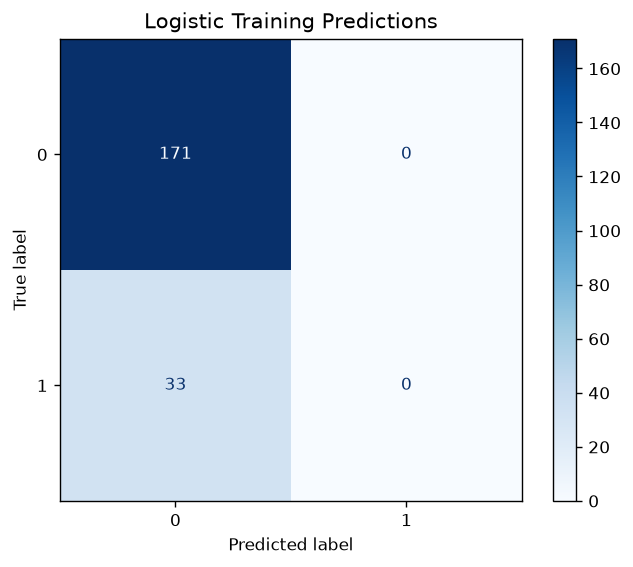

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_train_log,
    display_labels=log_mod.classes_,
    cmap="Blues"
)

plt.title("Logistic Training Predictions")
plt.show()

In [25]:
y_pred_test_log = log_mod.predict(X_test)
print(classification_report(y_test, y_pred_test_log))

              precision    recall  f1-score   support

           0       0.84      1.00      0.91        58
           1       0.00      0.00      0.00        11

    accuracy                           0.84        69
   macro avg       0.42      0.50      0.46        69
weighted avg       0.71      0.84      0.77        69



C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


### Class = 2

In [26]:
X = ha[features]
y = ha["cp_is_2"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["chol", "age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["trtbps"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

log_mod = make_pipeline(preprocessor, LogisticRegression())
log_mod.fit(X_train, y_train)

y_pred_train_log = log_mod.predict(X_train)
y_prob_train_log = log_mod.predict_proba(X_train)
log_prob_df = pd.DataFrame(
    y_prob_train_log,
    columns=log_mod.classes_,
    index=X_train.index
)

log_prob_df["Actual"] = y_train
log_prob_df["Predicted"] = y_pred_train_log

log_prob_df.head()

,0,1,Actual,Predicted
211,0.748183,0.251817,0,0
65,0.580914,0.419086,0,0
4,0.607168,0.392832,0,0
223,0.766788,0.233212,0,0
198,0.773937,0.226063,0,0


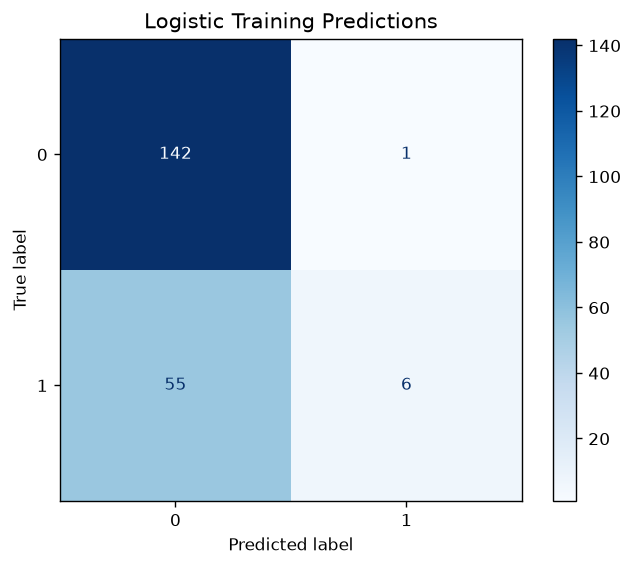

In [27]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_train_log,
    display_labels=log_mod.classes_,
    cmap="Blues"
)

plt.title("Logistic Training Predictions")
plt.show()

In [28]:
y_pred_test_log = log_mod.predict(X_test)
print(classification_report(y_test, y_pred_test_log))

              precision    recall  f1-score   support

           0       0.71      0.96      0.82        49
           1       0.33      0.05      0.09        20

    accuracy                           0.70        69
   macro avg       0.52      0.50      0.45        69
weighted avg       0.60      0.70      0.61        69



The OvR model was best at distingishing observations for Class = 3 with the highest accuracy between the 4 OvR models

## Q4: OvO

Reduce your dataset to only the `0` and `1` types of chest pain.

Then, fit a Logistic Regression to predict between the two groups, and estimate the ROC-AUC.  


In [29]:
from sklearn.metrics import roc_auc_score

In [30]:
ha_reduced = ha[ha["cp"].astype(int).isin([0, 1])].copy()

features = ["trtbps", "chol", "age"]

X = ha_reduced[features]
y = ha_reduced["cp"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["chol", "age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["trtbps"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

log_mod = make_pipeline(preprocessor, LogisticRegression())
log_mod.fit(X_train, y_train)

y_prob_train_log = log_mod.predict_proba(X_train)
y_prob = log_mod.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)
print(roc_auc)


0.7017045454545454


## Q5: OvO

Repeat Q4 comparing category `0` to `2`, and again to compare category `0` to `3`.  Which pair was the OvO approach best at distinguishing?

### 0 vs 2

In [31]:
ha_reduced = ha[ha["cp"].astype(int).isin([0, 2])].copy()

features = ["trtbps", "chol", "age"]

X = ha_reduced[features]
y = ha_reduced["cp"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["chol", "age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["trtbps"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

log_mod = make_pipeline(preprocessor, LogisticRegression())
log_mod.fit(X_train, y_train)

y_prob_train_log = log_mod.predict_proba(X_train)
y_prob = log_mod.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)
print(roc_auc)


0.5342261904761905


### 0 vs 3

In [32]:
ha_reduced = ha[ha["cp"].astype(int).isin([0, 3])].copy()

features = ["trtbps", "chol", "age"]

X = ha_reduced[features]
y = ha_reduced["cp"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["chol", "age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["trtbps"]),
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y)

log_mod = make_pipeline(preprocessor, LogisticRegression())
log_mod.fit(X_train, y_train)

y_prob_train_log = log_mod.predict_proba(X_train)
y_prob = log_mod.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)
print(roc_auc)


0.4625


The OvO approach was best at distinguishing between categories 0 and 3, likely because those are the most and least populated categories respectively.